# I-N40 - ISLES2022 Residual Encoder + component-centered sampling

- Input: DWI + ADC
- Single change: Sampling only: foreground patches centered on small connected components
- All other settings match I-N20
- 300 epochs; full-volume validation every 10 epochs from epoch 150
- Evaluate Top-3 +/-5 epochs, then save best-epoch probability maps
- Threshold 0.10-0.90: Dice, lesion recall/precision/F2, FP/scan, <0.1mL recall


In [1]:
from pathlib import Path
import json, os, subprocess, time
import pandas as pd

ROOT = Path("/home/stu03/workspace/model")
CONFIG = ROOT / "configs/experiments/ischemia/I-N40.yaml"
DATA_ROOT = Path("/home/stu03/workspace/datasets/ischemic/nnunet")
RESULTS_ROOT = ROOT / "runs/I-nnunet"
PYTHON = ROOT / ".venv/bin/python"
LAUNCHER = ROOT / "scripts/ischemia/training/run_i_n40.py"
MODEL_NAME = "nnUNetTrainerIschemiaComponentSampling__IschemiaPlansResidualEncoderComponentSampling__3d_fullres"
FOLD = RESULTS_ROOT / "Dataset502_ISLES2022" / MODEL_NAME / "fold_0"
PROGRESS = FOLD / "progress.json"
HISTORY = FOLD / "full_validation_history.json"
PID_FILE = ROOT / "runs/I-nnunet/I-N40/train.pid"
LOG_FILE = ROOT / "runs/I-nnunet/I-N40/train.log"

for name, path in {"config": CONFIG, "data": DATA_ROOT, "python": PYTHON, "launcher": LAUNCHER}.items():
    print(f"{name:10s} {path.exists()}  {path}")


config     True  /home/stu03/workspace/model/configs/experiments/ischemia/I-N40.yaml
data       True  /home/stu03/workspace/datasets/ischemic/nnunet
python     True  /home/stu03/workspace/model/.venv/bin/python
launcher   True  /home/stu03/workspace/model/scripts/ischemia/training/run_i_n40.py


## 1. Dry-run 및 Residual Encoder plans 확인


In [2]:
base = [str(PYTHON), str(LAUNCHER), "--config", str(CONFIG)]
subprocess.run(base + ["--dry-run"], cwd=ROOT, check=True)
prepare = ROOT / "scripts/ischemia/preprocessing/prepare_i_n20_plans.py"
subprocess.run([str(PYTHON), str(prepare), "--config", str(CONFIG), "--data-root", str(DATA_ROOT)], cwd=ROOT, check=True)
plans_path = DATA_ROOT / "nnUNet_preprocessed/Dataset502_ISLES2022/IschemiaPlansResidualEncoderV1.json"
plans = json.loads(plans_path.read_text())
arch = plans["configurations"]["3d_fullres"]["architecture"]
assert arch["network_class_name"].endswith("ResidualEncoderUNet")
assert arch["arch_kwargs"]["n_blocks_per_stage"] == [1, 3, 4, 6, 6]
print("Residual Encoder plans: PASS")
print(json.dumps(arch, indent=2))


{
  "experiment": "I-N40",
  "mode": "new",
  "output_folder": "/home/stu03/workspace/model/runs/I-nnunet/Dataset502_ISLES2022/nnUNetTrainerIschemiaComponentSampling__IschemiaPlansResidualEncoderComponentSampling__3d_fullres/fold_0",
  "prepare": [
    "/home/stu03/workspace/model/.venv/bin/python",
    "/home/stu03/workspace/model/scripts/ischemia/preprocessing/prepare_i_n20_plans.py",
    "--config",
    "/home/stu03/workspace/model/configs/experiments/ischemia/I-N40.yaml",
    "--data-root",
    "/home/stu03/workspace/datasets/ischemic/nnunet"
  ],
  "train": [
    "/home/stu03/workspace/model/.venv/bin/nnUNetv2_train",
    "502",
    "3d_fullres",
    "0",
    "-tr",
    "nnUNetTrainerIschemiaComponentSampling",
    "-p",
    "IschemiaPlansResidualEncoderComponentSampling",
    "-device",
    "cuda"
  ],
  "post_training_selection": [
    "/home/stu03/workspace/model/.venv/bin/python",
    "/home/stu03/workspace/model/scripts/ischemia/validation/evaluate_i_n40_neighborhood.py",
   

## 2. GPU 확인 및 학습 시작/재개

이미 PID가 실행 중이면 중복으로 시작하지 않습니다.


In [3]:
subprocess.run(["nvidia-smi"], check=False)
PID_FILE.parent.mkdir(parents=True, exist_ok=True)
LOG_FILE.parent.mkdir(parents=True, exist_ok=True)

def pid_running():
    if not PID_FILE.is_file():
        return False
    try:
        pid = int(PID_FILE.read_text().strip())
        return subprocess.run(["kill", "-0", str(pid)], capture_output=True).returncode == 0
    except (ValueError, OSError):
        return False

if pid_running():
    print("이미 실행 중 PID:", PID_FILE.read_text().strip())
else:
    log = LOG_FILE.open("a", encoding="utf-8")
    process = subprocess.Popen(base, cwd=ROOT, stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    PID_FILE.write_text(str(process.pid), encoding="utf-8")
    print("I-N40 시작 PID:", process.pid)
    print("로그:", LOG_FILE)


Tue Sep 15 07:33:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.84                 Driver Version: 595.84         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        Off |   00000000:01:00.0 Off |                  N/A |
|  0%   35C    P8             12W /  575W |    1170MiB /  32607MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 3. 실시간 진행률

셀 중지는 모니터만 멈추며 학습 프로세스는 계속 실행됩니다.


In [4]:
from IPython.display import clear_output, display

def read_json(path, default=None):
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (FileNotFoundError, json.JSONDecodeError):
        return {} if default is None else default

def fmt(seconds):
    if seconds is None:
        return "-"
    seconds = int(seconds)
    return f"{seconds//3600:02d}:{seconds%3600//60:02d}:{seconds%60:02d}"

while True:
    clear_output(wait=True)
    p = read_json(PROGRESS)
    history = read_json(HISTORY, [])
    running = pid_running()
    ranked = sorted(history, key=lambda x: x.get("macro_dice_positive", -1), reverse=True)[:3]
    row = {
        "실험": "I-N40", "상태": p.get("status", "starting" if running else "not_started"),
        "Epoch": f'{p.get("current_epoch", 0)}/{p.get("total_epochs", 300)}',
        "진행률(%)": p.get("progress_percent", 0), "ETA": fmt(p.get("eta_seconds")),
        "Online Dice": p.get("pseudo_dice"), "Online Recall": p.get("pseudo_recall"),
        "Composite": p.get("composite"), "Full Macro Dice": p.get("full_macro_dice"),
        "Best Full Dice": p.get("best_full_macro_dice"),
        "Top-3": [(x.get("epoch"), round(x.get("macro_dice_positive", 0), 4)) for x in ranked],
        "보존 CKPT": p.get("retained_epoch_checkpoints"), "PID": PID_FILE.read_text().strip() if running else "-",
    }
    display(pd.DataFrame([row]))
    if LOG_FILE.is_file():
        print("\n로그 마지막 15줄:\n", "".join(LOG_FILE.read_text(errors="replace").splitlines(True)[-15:]))
    status = p.get("status")
    if status in {"completed", "early_stopped", "failed"}:
        print("학습 프로세스 종료:", status)
        break
    if not running and p:
        print("PID가 종료되었습니다. 로그의 traceback을 확인하세요.")
        break
    time.sleep(10)


,실험,상태,Epoch,진행률(%),ETA,Online Dice,Online Recall,Composite,Full Macro Dice,Best Full Dice,Top-3,보존 CKPT,PID
0,I-N40,completed,300/300,100.0,00:00:00,0.829596,0.762781,0.796189,0.797414,0.805573,"[(160, 0.8056), (170, 0.8055), (240, 0.8006)]",37,2078913



로그 마지막 15줄:
 2026-09-15 13:46:10.884069: sub-strokecase0207, shape torch.Size([2, 67, 83, 72]), rank 0
2026-09-15 13:46:10.934318: predicting sub-strokecase0215
2026-09-15 13:46:10.936008: sub-strokecase0215, shape torch.Size([2, 67, 85, 68]), rank 0
2026-09-15 13:46:10.987492: predicting sub-strokecase0227
2026-09-15 13:46:10.988982: sub-strokecase0227, shape torch.Size([2, 60, 84, 66]), rank 0
2026-09-15 13:46:11.040888: predicting sub-strokecase0230
2026-09-15 13:46:11.042499: sub-strokecase0230, shape torch.Size([2, 65, 77, 70]), rank 0
2026-09-15 13:46:11.093079: predicting sub-strokecase0231
2026-09-15 13:46:11.095217: sub-strokecase0231, shape torch.Size([2, 64, 83, 72]), rank 0
2026-09-15 13:46:11.146780: predicting sub-strokecase0234
2026-09-15 13:46:11.148390: sub-strokecase0234, shape torch.Size([2, 65, 79, 62]), rank 0
2026-09-15 13:46:11.199012: predicting sub-strokecase0241
2026-09-15 13:46:11.200573: sub-strokecase0241, shape torch.Size([2, 60, 86, 73]), rank 0
2026-09-

## 4. 최종 선택 및 평가 결과 확인


In [5]:
selection = read_json(FOLD / "final_selection.json")
if not selection:
    print("아직 final_selection.json이 없습니다.")
else:
    selected = selection["selected"]
    display(pd.DataFrame([{
        "epoch": selected["epoch"],
        "macro_dice": selected["macro_dice_positive"],
        "lesion_detection_rate": selected["lesion_detection_rate"],
        "detected/total": f'{selected["detected_lesions"]}/{selected["total_lesions"]}',
        "mean_lesion_dice": selected["mean_lesion_dice"],
    }]))
    print("checkpoint:", FOLD / "checkpoint_best_dual_criteria.pth")
    print("상세 지표 계약:", json.loads(CONFIG.read_text()) if False else "I-N40.yaml evaluation.report 참조")


,epoch,macro_dice,lesion_detection_rate,detected/total,mean_lesion_dice
0,162,0.804107,0.625498,157/251,0.441759


checkpoint: /home/stu03/workspace/model/runs/I-nnunet/Dataset502_ISLES2022/nnUNetTrainerIschemiaComponentSampling__IschemiaPlansResidualEncoderComponentSampling__3d_fullres/fold_0/checkpoint_best_dual_criteria.pth
상세 지표 계약: I-N40.yaml evaluation.report 참조


## 5. Lesion Dice and detection rate by size

Bins: <0.01, 0.01-0.05, 0.05-0.1, 0.1-0.5, and >=0.5 mL. Missed lesions contribute Dice 0.


,size_group,gt_lesions,detected_lesions,detected/total,detection_rate,mean_lesion_dice,median_lesion_dice,median_volume_ml
0,<0.01 mL,18,1,1/18,0.055556,0.037037,0.000000,0.007151
1,0.01-0.05 mL,76,24,24/76,0.315789,0.212393,0.000000,0.030996
2,0.05-0.1 mL,30,18,18/30,0.600000,0.385410,0.236111,0.066661
3,0.1-0.5 mL,72,62,62/72,0.861111,0.592857,0.727273,0.200737
4,>=0.5 mL,55,52,52/55,0.945455,0.724090,0.829897,2.568000


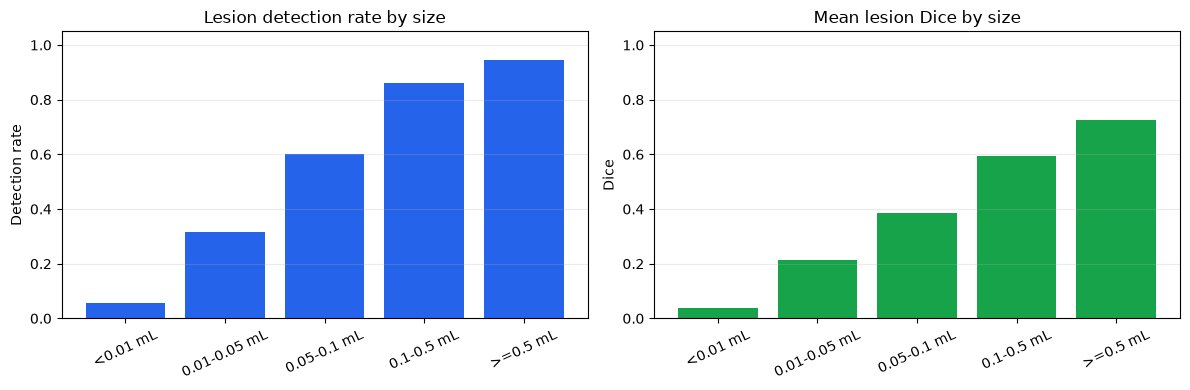

In [6]:
if not selection:
    print("최종 선택이 완료되지 않았습니다.")
else:
    size_path = Path(selection["selected"]["size_summary_csv"])
    size_df = pd.read_csv(size_path)
    display(size_df[[
        "size_group", "gt_lesions", "detected_lesions", "detected/total",
        "detection_rate", "mean_lesion_dice", "median_lesion_dice", "median_volume_ml",
    ]])

    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].bar(size_df["size_group"].astype(str), size_df["detection_rate"], color="#2563eb")
    axes[0].set(title="Lesion detection rate by size", ylabel="Detection rate", ylim=(0, 1.05))
    axes[1].bar(size_df["size_group"].astype(str), size_df["mean_lesion_dice"], color="#16a34a")
    axes[1].set(title="Mean lesion Dice by size", ylabel="Dice", ylim=(0, 1.05))
    for ax in axes:
        ax.tick_params(axis="x", rotation=25)
        ax.grid(axis="y", alpha=0.25)
    plt.tight_layout(); plt.show()


## 6. 최종 핵심 지표

Voxel overlap, 병변 검출, 경계 거리 및 병변 부피 오차를 함께 확인합니다.


In [7]:
metrics_summary = read_json(FOLD / "final_metrics/summary.json")
if not metrics_summary:
    print("final_metrics/summary.json이 아직 없습니다.")
else:
    macro = metrics_summary["macro"]
    keys = [
        ("dice", "Macro Dice"), ("iou", "Macro IoU"),
        ("recall_sensitivity", "Voxel Recall"), ("precision", "Voxel Precision"),
        ("specificity", "Specificity"), ("balanced_accuracy", "Balanced Accuracy"),
        ("mcc", "MCC"),
        ("hd95_mm", "HD95 (mm)"), ("assd_mm", "ASSD (mm)"),
        ("nsd_2mm", "NSD @ 2mm"), ("abs_volume_error_ml", "AVD (mL)"),
        ("relative_volume_error_pct", "RVD (%)"),
        ("volume_similarity", "Volume Similarity"),
        ("lesion_f1", "Macro Lesion F1"),
    ]
    overview = {label: macro[key]["mean"] for key, label in keys}
    overview.update({
        "Lesion Recall": metrics_summary["micro_lesion_recall"],
        "Lesion Precision": metrics_summary["micro_lesion_precision"],
        "FP/scan": metrics_summary["fp_per_scan"],
        "Complete miss cases": metrics_summary["complete_miss_cases"],
    })
    display(pd.DataFrame([overview]).T.rename(columns={0: "value"}))


,value
Macro Dice,0.809262
Macro IoU,0.700582
Voxel Recall,0.772112
Voxel Precision,0.904679
Specificity,0.999849
Balanced Accuracy,0.885980
MCC,0.822724
HD95 (mm),8.521418
ASSD (mm),1.637128
NSD @ 2mm,0.907556


## 7. Probability threshold evaluation

Evaluate the false-negative/false-positive trade-off. The recommended point maximizes lesion F2 under the configured FP/scan limit.


In [8]:
threshold_csv = FOLD / "final_metrics/threshold_sweep.csv"
threshold_json = FOLD / "final_metrics/threshold_summary.json"
if not threshold_csv.is_file():
    print("Threshold results are not available yet. Wait for post-training evaluation.")
else:
    threshold_df = pd.read_csv(threshold_csv)
    threshold_summary = read_json(threshold_json)
    display(pd.DataFrame([
        {"operating_point": "default 0.5", **threshold_summary["default_0_5"]},
        {"operating_point": "best Dice", **threshold_summary["best_macro_dice"]},
        {"operating_point": "recommended F2", **threshold_summary["recommended_lesion_f2"]},
    ]))
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(threshold_df["threshold"], threshold_df["macro_dice"], marker="o")
    axes[0].set(xlabel="Threshold", ylabel="Macro Dice", title="Dice by threshold")
    axes[1].plot(threshold_df["fp_per_scan"], threshold_df["lesion_recall"], marker="o")
    axes[1].set(xlabel="FP / scan", ylabel="Lesion recall", title="Recall-FP trade-off")
    axes[2].plot(threshold_df["threshold"], threshold_df["small_lesion_recall"], marker="o", label="<0.1 mL")
    axes[2].plot(threshold_df["threshold"], threshold_df["lesion_recall"], marker="o", label="All lesions")
    axes[2].set(xlabel="Threshold", ylabel="Recall", title="Small-lesion sensitivity")
    axes[2].legend()
    for ax in axes: ax.grid(alpha=0.25)
    plt.tight_layout(); plt.show()


Threshold results are not available yet. Wait for post-training evaluation.


## 8. Failure cases and volume agreement


,case_id,dice,recall_sensitivity,precision,lesion_recall,false_positive_lesions,hd95_mm,nsd_2mm,gt_volume_ml,pred_volume_ml,abs_volume_error_ml
10,sub-strokecase0068,0.326889,0.201735,0.861111,0.666667,1,38.178047,0.432781,3.688,0.864,2.824
15,sub-strokecase0092,0.428098,0.273928,0.979212,0.750000,0,16.613248,0.366442,66.032,18.472,47.560
18,sub-strokecase0098,0.454936,0.306358,0.883333,0.533333,1,31.470375,0.660944,1.384,0.480,0.904
11,sub-strokecase0076,0.562324,0.396301,0.967742,0.535714,6,25.735279,0.734463,6.056,2.480,3.576
8,sub-strokecase0050,0.675537,0.514286,0.984095,0.636364,3,6.000000,0.776081,15.400,8.048,7.352
36,sub-strokecase0234,0.680851,0.551724,0.888889,0.666667,0,32.972595,0.872340,0.232,0.144,0.088
6,sub-strokecase0040,0.727443,0.586285,0.958128,0.666667,2,6.000000,0.849194,10.616,6.496,4.120
20,sub-strokecase0138,0.750000,0.600000,1.000000,1.000000,0,2.000000,1.000000,0.200,0.120,0.080
2,sub-strokecase0018,0.781818,0.646617,0.988506,1.000000,0,2.828427,0.947115,1.064,0.696,0.368
19,sub-strokecase0118,0.784580,0.650376,0.988571,0.500000,1,4.472136,0.905405,6.384,4.200,2.184


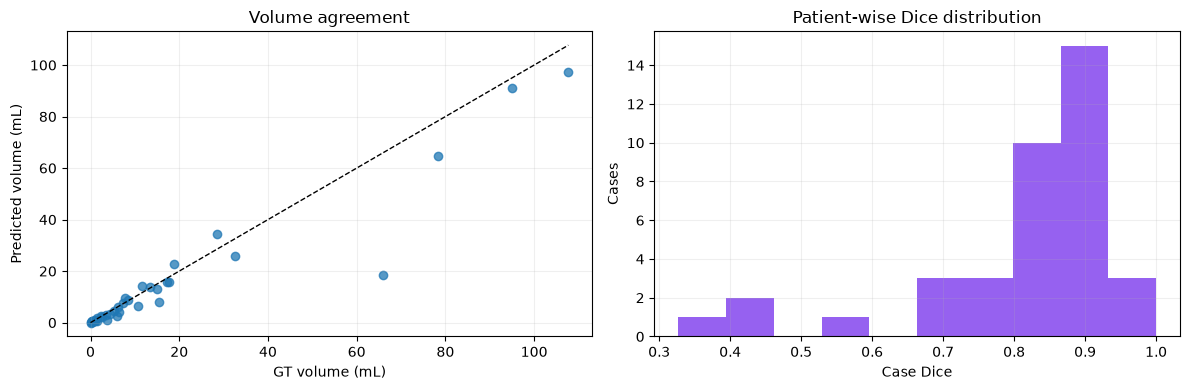

In [9]:
per_case_path = FOLD / "final_metrics/per_case.csv"
if not per_case_path.is_file():
    print("final_metrics/per_case.csv가 아직 없습니다.")
else:
    case_df = pd.read_csv(per_case_path)
    worst = case_df.sort_values(
        ["dice", "lesion_recall", "abs_volume_error_ml"],
        ascending=[True, True, False],
    ).head(10)
    display(worst[[
        "case_id", "dice", "recall_sensitivity", "precision",
        "lesion_recall", "false_positive_lesions", "hd95_mm",
        "nsd_2mm", "gt_volume_ml", "pred_volume_ml", "abs_volume_error_ml",
    ]])

    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(case_df["gt_volume_ml"], case_df["pred_volume_ml"], alpha=0.75)
    limit = max(case_df["gt_volume_ml"].max(), case_df["pred_volume_ml"].max())
    axes[0].plot([0, limit], [0, limit], "k--", linewidth=1)
    axes[0].set(xlabel="GT volume (mL)", ylabel="Predicted volume (mL)", title="Volume agreement")
    axes[1].hist(case_df["dice"], bins=10, color="#7c3aed", alpha=0.8)
    axes[1].set(xlabel="Case Dice", ylabel="Cases", title="Patient-wise Dice distribution")
    for ax in axes: ax.grid(alpha=0.2)
    plt.tight_layout(); plt.show()
